# DSA4212 Week 1: WikiText-103 → nanoGPT initial test

**Research question:** Under a fixed GPU training-time budget, can a smaller Transformer trained on more tokens outperform a larger model trained on fewer tokens?

**Purpose:** Validate the Colab T4, the existing WikiText-103 parquet data, GPT-2 BPE tokenization, nanoGPT scratch initialization, training, validation, and checkpoint persistence.

---
**Revision note (v2).** Part 1 (sections 1-9) is only a pipeline sanity check and is *not* used in any reported comparison.
Part 2 is the project. Sections 13b-20 were rewritten so that the notebook (i) tunes before it compares, (ii) selects the tokenizer and
best size from **validation** BPB automatically, (iii) tests whether the headline result survives changing the fixed batch size / LR,
(iv) adds non-neural baselines, and (v) evaluates every compared run once on the test split and exports lightweight results to `results/`.

## 1. GPU and environment

In [1]:
import sys, json, os, time, shutil, subprocess, re, platform
from pathlib import Path
import torch
print('Python:', sys.version.split()[0]); print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Select a GPU runtime in Runtime > Change runtime type.'
GPU_NAME = torch.cuda.get_device_name(0)
print('GPU:', GPU_NAME)
print('VRAM GB:', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print('CUDA:', torch.version.cuda)

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
VRAM GB: 15.64
CUDA: 13.0


## 2. Mount Drive and connect the repository
The four parquet files already live in `MyDrive/DSA4212/Dataset`.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
REPO = Path('/content/DSA4212_Group_10_Assignment')
DATA_DIR = Path('/content/drive/MyDrive/DSA4212/Dataset')
DRIVE_OUTPUT = Path('/content/drive/MyDrive/DSA4212/week1_smoke')

DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.is_dir(), f'Cannot find dataset: {DATA_DIR}'
if not (REPO / '.git').exists():
    subprocess.run(['git','clone','https://github.com/Alutare/DSA4212_Group_10_Assignment.git',str(REPO)],check=True)
print('Repo:', REPO)
print('Repo commit:', subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip())

Mounted at /content/drive
Repo: /content/DSA4212_Group_10_Assignment
Repo commit: ff126e23980924a74947f66c9ce2b93fe57f633f


## 3. Install required packages

In [3]:
subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(REPO/'requirements-data.txt')],check=True)
subprocess.run([sys.executable,'-m','pip','install','-q','tiktoken'],check=True)
import tiktoken, numpy as np, pyarrow.parquet as pq
print('tiktoken:', tiktoken.__version__ if hasattr(tiktoken,'__version__') else 'installed')

tiktoken: 0.14.0


## 4. Verify dataset loader
Make a symlink without copying the dataset.

In [4]:
LINK = REPO.parent / 'wikitext-103-raw-v1'
if LINK.is_symlink():
    assert LINK.resolve() == DATA_DIR.resolve(), f'Existing symlink points elsewhere: {LINK.resolve()}'
elif LINK.exists():
    assert LINK.resolve() == DATA_DIR.resolve(), f'Unexpected existing directory: {LINK}'
else:
    LINK.symlink_to(DATA_DIR, target_is_directory=True)
FILES = {'train':['train-00000-of-00002.parquet','train-00001-of-00002.parquet'],
         'val':['validation-00000-of-00001.parquet'],
         'test':['test-00000-of-00001.parquet']}
for split, names in FILES.items():
    for name in names:
        assert (DATA_DIR/name).is_file(), f'Missing {name}'
print('All four parquet files found.')
subprocess.run([sys.executable,str(REPO/'code/check_data.py')],cwd=REPO,check=True)

All four parquet files found.


CompletedProcess(args=['/usr/bin/python3', '/content/DSA4212_Group_10_Assignment/code/check_data.py'], returncode=0)

## 5. Tokenize the dataset once
Use GPT-2 BPE **tokenizer only**; no pretrained neural weights. Tokenize each parquet row, appending a newline separator as a separate tokenization unit. The same procedure applies to all splits. The output is uint16 token IDs. **Keep the test split untouched until final evaluation.**

In [5]:
ENC = tiktoken.get_encoding('gpt2')
assert ENC.n_vocab == 50257
print('GPT-2 vocabulary:', ENC.n_vocab, 'EOT:', ENC.eot_token)
PREPARED = REPO / 'data' / 'wikitext103'
PREPARED.mkdir(parents=True, exist_ok=True)
# One separator tokenization per row: independent of parquet batch boundaries.
NEWLINE_IDS = ENC.encode_ordinary('\n')
assert NEWLINE_IDS

def prepare_split(split, force=False):
    dest = PREPARED / f'{split}.bin'
    if dest.exists() and dest.stat().st_size > 0 and not force:
        print(split, 'cached:', dest.stat().st_size // 2, 'tokens')
        return
    temp = dest.with_suffix('.bin.partial')
    count = 0
    with open(temp,'wb') as out:
        for filename in FILES[split]:
            pf = pq.ParquetFile(DATA_DIR / filename)
            for batch in pf.iter_batches(batch_size=512,columns=['text']):
                texts = batch.column(0).to_pylist()
                ids = []
                for text in texts:
                    if text is None:
                        continue
                    ids.extend(ENC.encode_ordinary(text))
                    ids.extend(NEWLINE_IDS)
                np.asarray(ids,dtype=np.uint16).tofile(out)
                count += len(ids)
    temp.replace(dest)
    print(split, 'wrote:', count, 'tokens')

for split in ('train','val','test'):
    prepare_split(split)
for split in ('train','val','test'):
    a=np.memmap(PREPARED/f'{split}.bin',dtype=np.uint16,mode='r')
    assert len(a)>129 and int(a.max())<ENC.n_vocab
    print(split, 'tokens:',len(a),'first:',a[:8].tolist())

GPT-2 vocabulary: 50257 EOT: 50256
train wrote: 119721490 tokens
val wrote: 251049 tokens
test wrote: 287645 tokens
train tokens: 119721490 first: [198, 796, 569, 18354, 7496, 17740, 6711, 796]
val tokens: 251049 first: [198, 796, 8074, 20272, 9106, 3876, 385, 796]
test tokens: 287645 first: [198, 796, 5199, 347, 2852, 353, 796, 220]


## 6. Clone a pinned nanoGPT implementation
`init_from=scratch` ensures random weights.

In [6]:
NANO = Path('/content/nanoGPT')
if not (NANO/'.git').exists():
    subprocess.run(['git','clone','https://github.com/karpathy/nanoGPT.git',str(NANO)],check=True)
PINNED_SHA='3adf61e154c3fe3fca428ad6bc3818b27a3b8291'   # commit used in Part 1 (reproducibility)
subprocess.run(['git','-C',str(NANO),'checkout','-q',PINNED_SHA],check=True)
NANO_SHA=subprocess.check_output(['git','-C',str(NANO),'rev-parse','HEAD'],text=True).strip()
print('nanoGPT commit:',NANO_SHA)
NANO_DATA=NANO/'data'/'wikitext103'
NANO_DATA.mkdir(parents=True,exist_ok=True)
for name in ('train.bin','val.bin'):
    src=PREPARED/name
    dst=NANO_DATA/name
    if not dst.exists() or dst.stat().st_size != src.stat().st_size:
        shutil.copy2(src,dst)
print('Training binaries ready:', [(p.name,p.stat().st_size) for p in NANO_DATA.glob('*.bin')])

nanoGPT commit: 3adf61e154c3fe3fca428ad6bc3818b27a3b8291
Training binaries ready: [('train.bin', 239442980), ('val.bin', 502098)]


## 7. Small GPT: 200-step smoke test
This is **not** a fixed-time final run. Model dimensions: 4 layers, 4 heads, 128 embedding width, 128 context, batch 16. GPT-2 BPE vocabulary means the embedding matrix alone is large; always report the actual parameter count.

Run time depends on GPU availability. Training output is written to a log and displayed after completion. If an OOM occurs, reduce batch size to 8 and record the change.

In [7]:
OUT=NANO/'out-week1-smoke'
LOG=REPO/'week1_smoke_train.log'
CMD=[sys.executable,'train.py',
    '--dataset=wikitext103','--out_dir=out-week1-smoke',
    '--init_from=scratch','--n_layer=4','--n_head=4','--n_embd=128',
    '--block_size=128','--batch_size=16','--gradient_accumulation_steps=1',
    '--learning_rate=3e-4','--max_iters=200','--warmup_iters=20',
    '--lr_decay_iters=200','--min_lr=3e-5','--eval_interval=50',
    '--eval_iters=20','--log_interval=10','--dtype=float16',
    '--compile=False','--wandb_log=False','--device=cuda']
print('Command:', ' '.join(CMD))
print('Training; please wait...')
start=time.perf_counter()
with open(LOG,'w') as f:
    result=subprocess.run(CMD,cwd=NANO,stdout=f,stderr=subprocess.STDOUT)
wall_seconds=time.perf_counter()-start
print('Exit code:',result.returncode,'Wall time (s, includes validation and setup):',round(wall_seconds,1))
logtext=LOG.read_text(errors='replace')
print(logtext[-10000:])
if result.returncode:
    raise RuntimeError('Training failed; inspect the log tail above.')

Command: /usr/bin/python3 train.py --dataset=wikitext103 --out_dir=out-week1-smoke --init_from=scratch --n_layer=4 --n_head=4 --n_embd=128 --block_size=128 --batch_size=16 --gradient_accumulation_steps=1 --learning_rate=3e-4 --max_iters=200 --warmup_iters=20 --lr_decay_iters=200 --min_lr=3e-5 --eval_interval=50 --eval_iters=20 --log_interval=10 --dtype=float16 --compile=False --wandb_log=False --device=cuda
Training; please wait...
Exit code: 0 Wall time (s, includes validation and setup): 21.2
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(dtype == 'float16'))
Overriding: dataset = wikitext103
Overriding: out_dir = out-week1-smoke
Overriding: init_from = scratch
Overriding: n_layer = 4
Overriding: n_head = 4
Overriding: n_embd = 128
Overriding: block_size = 128
Overriding: batch_size = 16
Overriding: gradient_accumulation_steps = 

## 8. Check the validation curve and model size

Validation points: [(0, 10.8342), (50, 9.1225), (100, 7.9886), (150, 7.5889), (200, 7.4822)]


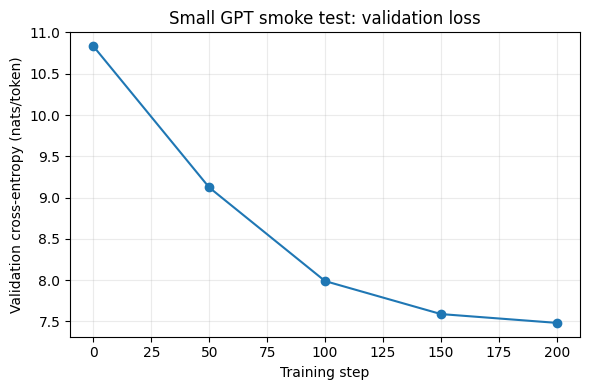

Start/end validation loss: 10.8342 7.4822
Improved: True


In [8]:
import matplotlib.pyplot as plt
pairs=[(int(a),float(b)) for a,b in re.findall(r'step (\d+): train loss [0-9.]+, val loss ([0-9.]+)',logtext)]
print('Validation points:',pairs)
assert len(pairs)>=2, 'No validation curve found; inspect training log.'
xs,ys=zip(*pairs)
plt.figure(figsize=(6,4))
plt.plot(xs,ys,marker='o')
plt.xlabel('Training step');plt.ylabel('Validation cross-entropy (nats/token)')
plt.title('Small GPT smoke test: validation loss')
plt.grid(alpha=.25);plt.tight_layout()
FIG=REPO/'week1_smoke_validation.png'
plt.savefig(FIG,dpi=160)
plt.show()
print('Start/end validation loss:',ys[0],ys[-1])
print('Improved:',ys[-1]<ys[0])

In [9]:
# Add nanoGPT to Python path
sys.path.insert(0, "/content/nanoGPT")

from model import GPT, GPTConfig

print("nanoGPT model imported successfully!")

# Correct checkpoint directory
OUT = Path("/content/nanoGPT/out-week1-smoke")
CKPT = OUT / "ckpt.pt"

assert CKPT.exists(), f"No checkpoint at {CKPT}"

# Load checkpoint
ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)

# Reconstruct model
model = GPT(GPTConfig(**ckpt["model_args"]))
model.load_state_dict(ckpt["model"])

# Calculate parameters
params = sum(p.numel() for p in model.parameters())

print("Parameter count:", f"{params:,}")
print("Checkpoint step:", ckpt["iter_num"])
print("Best validation loss:", ckpt["best_val_loss"])
print("Training tokens per optimizer step:", 16 * 128)
print("Approximate tokens through 200 updates:", 200 * 16 * 128)

del model, ckpt

nanoGPT model imported successfully!
number of parameters: 7.23M
Parameter count: 7,242,880
Checkpoint step: 200
Best validation loss: tensor(7.4822)
Training tokens per optimizer step: 2048
Approximate tokens through 200 updates: 409600


## 9. Back up checkpoint, metrics, and training log

In [10]:
import hashlib
repo_sha=subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip()
metadata={
    'purpose':'week1_smoke_test_not_final',
    'gpu':GPU_NAME,'torch':torch.__version__,'python':platform.python_version(),
    'repo_commit':repo_sha,'nanogpt_commit':NANO_SHA,
    'dataset':'WikiText-103 raw parquet from MyDrive/DSA4212/Dataset',
    'tokenizer':'tiktoken GPT-2 BPE','vocab_size':ENC.n_vocab,
    'preprocessing':'each non-null parquet text row encoded separately followed by encoded newline',
    'model':{'n_layer':4,'n_head':4,'n_embd':128,'block_size':128,'params':params},
    'train':{'batch_size':16,'gradient_accumulation_steps':1,'learning_rate':3e-4,
             'max_iters_configured':200,'dtype':'float16','compile':False},
    'wall_seconds_including_eval_and_setup':round(wall_seconds,3),
    'validation_loss_by_step':dict(pairs),
    'checkpoint_iteration':int(torch.load(CKPT,map_location='cpu',weights_only=False)['iter_num']),
    'note':'nanoGPT original stopping logic may execute one extra update; not an exact-budget run.'
}
META=REPO/'week1_smoke_metrics.json'
META.write_text(json.dumps(metadata,indent=2))
for source in (CKPT,LOG,FIG,META):
    shutil.copy2(source,DRIVE_OUTPUT / ('small_smoke_ckpt.pt' if source==CKPT else source.name))
print('Backed up:', [p.name for p in DRIVE_OUTPUT.iterdir()])

Backed up: ['week1_smoke_train.log', 'small_smoke_ckpt.pt', 'week1_smoke_validation.png', 'week1_smoke_metrics.json']


---
# PART 2 — Budgeted experiments (builds on Part 1 above)

Part 1 (above, unchanged) validated the pipeline: T4, WikiText-103 parquet, GPT-2 BPE tokenisation, nanoGPT scratch init, checkpointing.
Part 2 adds what the project brief requires and nanoGPT's stock `train.py` does not provide:

* **fixed wall-clock training budget** per run (time-driven LR schedule, resumable without resetting the budget)
* **bits-per-byte** evaluation (comparable across tokenizers) on full validation / test splits
* experiment studies: tokenizer, model size vs tokens, depth vs width, efficiency, seeds, ...

Part 2 uses the new `code/` folder in the same GitHub repo. **Push `code/` and `requirements.txt` to the repo before running.**
Every long step is resumable and skips finished runs, so after a Colab disconnect re-run Part 1 cells 1–4 (GPU, Drive/repo, installs) and the Part 2 setup cell, then the study cell.

## 10. Part 2 setup (reuses `REPO`, `DATA_DIR`, `PREPARED` from Part 1)

In [11]:
import os, sys, shutil, subprocess
from pathlib import Path

DRIVE   = '/content/drive/MyDrive/DSA4212'
PARQUET = str(DATA_DIR)                  # same Drive folder Part 1 used
RUNS    = f'{DRIVE}/runs'                # all run results live on Drive
TOKS    = f'{DRIVE}/tokenizers'
DATA    = '/content/data'                # fast local copy of the new .bin files
for d in (RUNS, TOKS, DATA): Path(d).mkdir(parents=True, exist_ok=True)

subprocess.run(['git', '-C', str(REPO), 'pull'], check=False)      # pick up the pushed code/ folder
CODE = f'{REPO}/code'
assert Path(f'{CODE}/train.py').exists(), "code/train.py not found: push the new code/ folder to GitHub first"
os.chdir(CODE); sys.path.insert(0, CODE)
print('Using code from', CODE)

Using code from /content/DSA4212_Group_10_Assignment/code


In [12]:
!pip install -q tiktoken tokenizers pyarrow pandas matplotlib && python test_utils.py

plan ok n=1000 T=64 stride=64: 16 windows
plan ok n=1001 T=64 stride=64: 16 windows
plan ok n=1000 T=64 stride=16: 60 windows
plan ok n=999 T=64 stride=32: 31 windows
plan ok n=65 T=64 stride=64: 1 windows
plan ok n=66 T=64 stride=10: 2 windows
plan ok n=5000 T=128 stride=128: 40 windows
plan ok n=5000 T=128 stride=32: 154 windows
ALL TESTS PASSED


## 11. Declared compute budget  *(copy this into the first page of the report)*
Defined once in `code/experiments.py`.

In [13]:
import experiments as E
print("Hardware      :", E.HARDWARE)
print("Budget / run  :", E.BUDGET_SECONDS, "s of optimisation-step wall-clock (eval + checkpoint time excluded; compile time included)")
print("Tuning runs   :", round(E.BUDGET_SECONDS*E.TUNE_FRACTION), "s each (preliminary, excluded from the budget)")
print("Init          : random (no pretrained weights/embeddings); tokenizers trained on WikiText train only or GPT-2 BPE merges (no neural components)")
print("Metric        : validation/test bits-per-byte (tokeniser-independent) + perplexity")

Hardware      : 1x NVIDIA Tesla T4 (16 GB), Google Colab, fp16 mixed precision
Budget / run  : 1800 s of optimisation-step wall-clock (eval + checkpoint time excluded; compile time included)
Tuning runs   : 300 s each (preliminary, excluded from the budget)
Init          : random (no pretrained weights/embeddings); tokenizers trained on WikiText train only or GPT-2 BPE merges (no neural components)
Metric        : validation/test bits-per-byte (tokeniser-independent) + perplexity


## 12. GPT-2 BPE data (cached on Drive after the first time)

In [14]:
import shutil
def ensure_data(name, tokenizer):
    local, cached = Path(DATA)/name, Path(DRIVE)/'data'/name
    if (local/'meta.json').exists(): return print(name, 'ready (local)')
    if (cached/'meta.json').exists():
        shutil.copytree(cached, local); return print(name, 'copied from Drive')
    !python prepare_data.py --data_dir {PARQUET} --tokenizer {tokenizer} --name {name} --out_root {DATA}
    shutil.copytree(local, cached, dirs_exist_ok=True)
ensure_data('gpt2', 'gpt2')

gpt2/train: 1,801,350 rows, 119,721,490 tokens, 541,096,899 bytes, 4.520 bytes/token, roundtrip mismatches 0/5000
gpt2/val: 3,760 rows, 251,049 tokens, 1,148,008 bytes, 4.573 bytes/token, roundtrip mismatches 0/1000
gpt2/test: 4,358 rows, 287,645 tokens, 1,292,014 bytes, 4.492 bytes/token, roundtrip mismatches 0/1262
wrote /content/data/gpt2/meta.json


**Continuity check with Part 1:** the new `gpt2` tokenisation must contain exactly the same tokens as the Part 1 files.

In [15]:
import numpy as np, json
meta = json.load(open(f'{DATA}/gpt2/meta.json'))
for split in ('train', 'val', 'test'):
    old = np.memmap(PREPARED/f'{split}.bin', dtype=np.uint16, mode='r')
    new_ = np.memmap(f'{DATA}/gpt2/{split}.bin', dtype=np.uint16, mode='r')
    assert len(old) == len(new_), (split, len(old), len(new_))
    assert (old[:100000] == new_[:100000]).all()
    print(f"{split}: {len(new_):,} tokens identical to Part 1 | {meta['bytes'][split]:,} bytes | "
          f"{meta['bytes'][split]/len(new_):.3f} bytes/token | round-trip mismatches {meta['roundtrip_mismatches'][split]}")

train: 119,721,490 tokens identical to Part 1 | 541,096,899 bytes | 4.520 bytes/token | round-trip mismatches 0/5000
val: 251,049 tokens identical to Part 1 | 1,148,008 bytes | 4.573 bytes/token | round-trip mismatches 0/1000
test: 287,645 tokens identical to Part 1 | 1,292,014 bytes | 4.492 bytes/token | round-trip mismatches 0/1262


## 13. Custom tokenizers (trained on WikiText **train** only; not part of the run budget)

In [ ]:
for V, name in [(4096,'bpe4k'), (8192,'bpe8k'), (16384,'bpe16k'), (32768,'bpe32k')]:
    path = f'{TOKS}/{name}.json'
    if not Path(path).exists():
        !python train_tokenizer.py --data_dir {PARQUET} --vocab_size {V} --out {path}
    ensure_data(name, path)

[00:00:00] Tokenize words                 ██████████████████ 598976   /   598976
[00:00:01] Count pairs                    ██████████████████ 598976   /   598976
[00:00:04] Compute merges                 ██████████████████ 3840     /     3840
saved /content/drive/MyDrive/DSA4212/tokenizers/bpe4k.json: vocab=4096, sample -> 31 tokens, lossless OK
bpe4k/train: 1,801,350 rows, 154,868,828 tokens, 541,096,899 bytes, 3.494 bytes/token, roundtrip mismatches 0/5000
bpe4k/val: 3,760 rows, 324,088 tokens, 1,148,008 bytes, 3.542 bytes/token, roundtrip mismatches 0/1000
bpe4k/test: 4,358 rows, 370,415 tokens, 1,292,014 bytes, 3.488 bytes/token, roundtrip mismatches 0/1262
wrote /content/data/bpe4k/meta.json
[00:00:00] Tokenize words                 ██████████████████ 598976   /   598976
[00:00:01] Count pairs                    ██████████████████ 598976   /   598976
[00:00:04] Compute merges                 ██████████████████ 7936     /     7936
saved /content/drive/MyDrive/DSA4212/tokenizers/bpe

## 13b. Tokenizer control + tokenizer statistics
The five tokenizers are **GPT-2 BPE (50 257, trained on WebText)** and four byte-level BPEs trained by us on WikiText-103 *train* (4k/8k/16k/32k).
Vocabulary size and "merges learned in-domain" are confounded between GPT-2 and the rest, so we add **bpe50k**: same vocabulary size as GPT-2, merges learned on WikiText.
Comparing `bpe50k` with `gpt2` isolates the domain effect; comparing `bpe50k` with `bpe4k..32k` isolates the size effect.

In [ ]:
# control tokenizer (same size as GPT-2, in-domain merges). ~1 tokenisation pass.
!python train_tokenizer.py --data_dir {PARQUET} --vocab_size 50257 --out {TOKS}/bpe50k.json
ensure_data('bpe50k', f'{TOKS}/bpe50k.json')

In [ ]:
# Table for the report: how each tokenizer trades sequence length against embedding size (m model: n_embd=384)
import pandas as pd, json
rows = []
for name in ['gpt2','bpe4k','bpe8k','bpe16k','bpe32k','bpe50k']:
    mp = Path(DATA)/name/'meta.json'
    if not mp.exists():
        print('MISSING (re-run ensure_data):', name); continue
    m = json.load(open(mp)); V = m['n_vocab']; Vp = -(-V//64)*64
    rows.append(dict(tokenizer=name, vocab=V, train_tokens_M=m['tokens']['train']/1e6,
                     bytes_per_token=m['bytes']['train']/m['tokens']['train'],
                     emb_params_M_at_E384=Vp*384/1e6,
                     emb_share_of_flops_per_token_m=(6*Vp*384)/(6*(Vp*384+12*6*384**2)+12*6*384*256)))
tok_table = pd.DataFrame(rows); display(tok_table.round(3))
tok_table.to_csv(f'{DRIVE}/tokenizer_stats.csv', index=False)

## 14. Throughput benchmark, budget allocation and smoke test
The benchmark uses synthetic batches, so it **over-estimates** real throughput slightly (no data loading). It tells you, *before* spending GPU hours, how many tokens,
epochs and optimiser steps each model size gets in the declared budget. Watch the `steps` column: with a fixed 16 384 tokens/step the biggest model gets only a few hundred
updates, which would handicap it for reasons unrelated to model size (this is tested in section 16-D).

In [ ]:
!python benchmark.py --sizes xs s m l xl --vocabs 50257 16384 --out {RUNS}/benchmark.csv

In [ ]:
# precision / compile efficiency measured as THROUGHPUT (cheap) instead of three 30-minute runs
!python benchmark.py --sizes m --vocabs 50257 --dtype float32 --out {RUNS}/benchmark_fp32.csv
!python benchmark.py --sizes m --vocabs 50257 --compile --out {RUNS}/benchmark_fp16_compile.csv

In [ ]:
import importlib, pandas as pd
importlib.reload(E)
bm = pd.read_csv(f'{RUNS}/benchmark.csv')
def _tps(s): c = E.cfg(s); return c['batch_size']*c['grad_accum']*c['block_size']
def _flops_tok(r):
    c = E.cfg(r['size']); return 6*(r['params_total']-c['block_size']*c['n_embd']) + 12*c['n_layer']*c['n_embd']*c['block_size']
bm['tokens_per_step']  = bm['size'].map(_tps)
bm['steps_in_budget']  = bm.tokens_in_budget/bm.tokens_per_step
bm['PFLOPs_in_budget'] = bm.apply(_flops_tok, axis=1)*bm.tokens_in_budget/1e15
bm['tok_per_param_total'] = bm.tokens_in_budget/bm.params_total
display(bm.round(2))
print('Sizes with < 1500 optimiser steps in the budget (batch-size confound!):', sorted(set(bm[bm.steps_in_budget<1500]['size'])))
for f in ('benchmark_fp32.csv','benchmark_fp16_compile.csv'):
    d = pd.read_csv(f'{RUNS}/{f}'); print(f, '->', round(d.tok_per_s.iloc[0]), 'tok/s (m, gpt2 vocab)')
bm.to_csv(f'{DRIVE}/benchmark_annotated.csv', index=False)

In [ ]:
!python run_experiments.py --study size --stage smoke --only size_xs --tok gpt2 --data_root {DATA} --out_root {RUNS} --budget 60

## 15. Non-neural baselines  *(the brief asks for "appropriate baselines")*
gzip/bz2/xz and token unigram / interpolated-bigram models give BPB reference points on exactly the same byte stream. A transformer that does not clearly beat the bigram is broken or undertrained.

In [ ]:
!python baselines.py --parquet_dir {PARQUET} --data_root {DATA} --tokenizers gpt2 bpe4k --out {RUNS}/baselines.json

## 16. Studies — order, rationale and T4 time (30-min final runs, 5-min tuning runs)
| Tier | Step | Question | Runs | T4 time |
|---|---|---|---|---|
| core | A. LR tuning | is the LR per size reasonable? (otherwise "small vs large" is an LR artefact) | 3 sizes x 5 LRs x 5 min | 1.25 h |
| core | B. tokenizer | which vocabulary size is best per unit of compute? | 5 | 2.5 h |
| core | C. size (**headline**) | smaller model + more tokens vs larger + fewer? | 5 | 2.5 h |
| core | D. batch size at XL | does the headline survive a smaller batch (more steps) for the big model? | 3 | 1.5 h |
| core | E. seeds | is the best-vs-runner-up gap larger than seed noise? | 3 | 1.5 h |
| extra | F. data repetition (xs) | what happens when the small model re-reads the corpus? | 5 | 2.5 h |
| extra | G. tokenizer control + size robustness on GPT-2 | is the size result tokenizer-dependent? | 1 + 2 | 1.5 h |
| extra | H. shape | depth vs width at ~10M non-embedding params | 4 | 2 h |
| extra | I. compile / context | efficiency, context length | 1 + 4 | 2.5 h |

Do core first. With a 10-page limit, depth on core + two extras beats shallow coverage of everything. A failed or null result is fine if it is investigated and reported.
**Note:** `size_m` (seed 1337) and `shape_base6` / `best_m_s1337` are the *same* configuration, so they double as a free check of how much wall-clock budgeting alone changes the result.

### 16-A. Learning-rate tuning (5-minute runs, validation BPB) — before any final run

In [ ]:
# LR is tuned at three sizes on a mid-sized vocabulary (bpe16k); the other two sizes get a log-log interpolation.
# selection.py writes results/tuned_lr.json, which experiments.py picks up automatically (so the repo matches what was run).
import importlib
for s in ['xs', 'm', 'xl']:
    !python run_experiments.py --study lr --stage tune --data_root {DATA} --out_root {RUNS} --tok bpe16k --size {s}
!python selection.py tune_lr --root {RUNS} --out {REPO}/results/tuned_lr.json
importlib.reload(E)
print('LRs now used:', {k: v['lr'] for k, v in E.SIZES.items()})

If a tuned LR sits at the **edge** of the grid, extend the grid in `experiments.py` and rerun that size before continuing.
Limitation to report: 5-minute tuning runs may favour higher LRs than 30-minute runs.

### 16-B. Tokenizer study → automatically choose `TOK` from validation BPB

In [ ]:
!python run_experiments.py --study tokenizer --stage final --data_root {DATA} --out_root {RUNS}
out = subprocess.check_output([sys.executable, 'selection.py', 'best', '--root', RUNS, '--stage', 'final', '--study', 'tokenizer'], text=True)
print(out); TOK = out.strip().splitlines()[-1]; print('Chosen tokenizer (best validation BPB):', TOK)

In [ ]:
# the gap between first and second place: compare with the seed std from 16-E before claiming a winner
!python analyze.py --root {RUNS} --stage final --out {DRIVE}/figures

### 16-C. Model size vs tokens — **the headline experiment**

In [ ]:
SIZE_ARGS = f"--data_root {DATA} --out_root {RUNS} --tok {TOK}"
!python run_experiments.py --study size --stage final {SIZE_ARGS}
out = subprocess.check_output([sys.executable, 'selection.py', 'best', '--root', RUNS, '--stage', 'final', '--study', 'size'], text=True)
print(out); SIZE_BEST = out.strip().splitlines()[-1]; print('Best size by validation BPB:', SIZE_BEST)

### 16-D. Sensitivity of the headline to the *fixed* batch size
The size study holds 16 384 tokens/step for every model. The XL model then makes few updates, which may be the real reason it loses. We rerun XL with 4k / 16k / 64k tokens per step (LR scaled by sqrt of the batch ratio – an assumption to state).
If XL improves a lot with 4k tokens/step, the conclusion "larger models lose under this budget" is conditional on the batch size, and must be reported that way.

In [ ]:
!python run_experiments.py --study batch --stage final --data_root {DATA} --out_root {RUNS} --tok {TOK} --size xl

### 16-E. Seeds of the best configuration (error bars)

In [ ]:
!python run_experiments.py --study seeds --stage final --seeds 1337 1338 1339 --data_root {DATA} --out_root {RUNS} --tok {TOK} --size {SIZE_BEST}

### 16-F. (extra) Repeated data: xs model on 1 %, 3 %, 10 %, 30 %, 100 % of the corpus

In [ ]:
!python run_experiments.py --study data --stage final --data_root {DATA} --out_root {RUNS} --tok {TOK}

### 16-G. (extra) Is the size result tokenizer-dependent? + tokenizer control
The embedding table is most of a small model (it takes ~90 % of the XS model's parameters with the GPT-2 vocabulary), so the best size may depend on the tokenizer.
We rerun the two extreme sizes on GPT-2 (skip if `TOK == 'gpt2'`) and run the bpe50k control.

In [ ]:
if TOK != 'gpt2':
    for s in ['xs', 'xl']:
        !python run_experiments.py --study size --stage final --only size_{s}_gpt2 --data_root {DATA} --out_root {RUNS} --tok gpt2
!python run_experiments.py --study tokenizer_control --stage final --data_root {DATA} --out_root {RUNS}

### 16-H. (extra) Depth vs width at ~10M non-embedding parameters

In [ ]:
!python run_experiments.py --study shape --stage final --data_root {DATA} --out_root {RUNS} --tok {TOK} --size m

### 16-I. (optional) compile (throughput gain measured in 14; one full run shows the effect on BPB) and context length

In [ ]:
!python run_experiments.py --study efficiency --stage final --only fp16compile --data_root {DATA} --out_root {RUNS} --tok {TOK} --size m
!python run_experiments.py --study context --stage final --data_root {DATA} --out_root {RUNS} --tok {TOK} --size m

## 17. Tables and figures (validation only)

In [ ]:
!python analyze.py --root {RUNS} --stage final --out {DRIVE}/figures
from IPython.display import Image, display
for f in sorted(Path(f'{DRIVE}/figures').glob('*_summary.png')): display(Image(str(f)))

### 17b. Headline analysis: where is the optimum, how many tokens per parameter, is the gap bigger than noise?
Chinchilla's ~20 tokens/parameter rule counts *total* parameters; Kaplan-style analyses count *non-embedding* parameters. At this scale the two differ by a large factor
(Pearce & Song 2024), so both are tabulated. Do not interpret the quadratic fit beyond the sampled range – it only locates the minimum roughly.

In [ ]:
import numpy as np, selection as S
rs = [r for r in S.load_results(RUNS, 'final', 'size') if r['tokenizer_name'] == TOK]
rows = []
for r in rs:
    rows.append(dict(size=S.size_key(r['args']), params_total_M=r['params']['total']/1e6, params_nonemb_M=r['params']['non_embedding']/1e6,
                     steps=r['steps'], tokens_M=r['tokens_seen']/1e6, epochs=r['epochs'],
                     tok_per_param_total=r['tokens_seen']/r['params']['total'], tok_per_param_nonemb=r['tokens_per_param_nonemb'],
                     tok_s=r['tokens_per_sec'], mfu=r['mfu'], PFLOPs=r['flops_per_token']*r['tokens_seen']/1e15,
                     val_bpb=r['val']['bpb'], diverged=r['diverged']))
head = pd.DataFrame(rows).sort_values('params_nonemb_M'); display(head.round(3))
head.to_csv(f'{DRIVE}/headline_size_table.csv', index=False)
x = np.log10(head.params_nonemb_M.values*1e6); y = head.val_bpb.values
if len(x) >= 4:
    a, b, c = np.polyfit(x, y, 2)
    if a > 0:
        xo = -b/(2*a); print(f'quadratic fit: minimum at ~{10**xo/1e6:.1f}M non-embedding params (sampled range {10**x.min()/1e6:.1f}M-{10**x.max()/1e6:.1f}M)')
    else:
        print('fit is concave: optimum is at the edge of the sampled range -> extend the sizes before concluding')
seed_rs = S.load_results(RUNS, 'final', 'seeds')
if len(seed_rs) >= 2:
    sd = np.std([r['val']['bpb'] for r in seed_rs], ddof=1); srt = head.sort_values('val_bpb')
    gap = srt.val_bpb.iloc[1]-srt.val_bpb.iloc[0]
    print(f'seed std of the best config = {sd:.4f} BPB; gap best vs runner-up ({srt.iloc[0]["size"]} vs {srt.iloc[1]["size"]}) = {gap:.4f} = {gap/sd:.1f} std')

In [ ]:
# baselines vs the best model (validation BPB)
bl = json.load(open(f'{RUNS}/baselines.json'))
print('compressors (val):', {k: round(v, 3) for k, v in bl['compress_val'].items()})
for t in ('gpt2', 'bpe4k'):
    print(t, {k: round(v, 3) for k, v in bl[t].items() if k.endswith('val_bpb')})
print('best model val BPB:', round(head.val_bpb.min(), 4))

## 18. FINAL test evaluation  *(test split touched only here; one evaluation per run)*
The brief asks to compare configurations on the same test data, so every run that appears in a reported comparison (tokenizer, size, seeds) is evaluated once.
`evaluate.py` requires `--final` and refuses a second evaluation of the same run. **Do not change any choice after seeing these numbers.**

In [ ]:
TEST_STUDIES = ['tokenizer', 'tokenizer_control', 'size', 'seeds']
for st in TEST_STUDIES:
    for rd in sorted(Path(f'{RUNS}/final/{st}').glob('*')):
        if not (rd/'result.json').exists() or (rd/'test_result.json').exists(): continue
        tk = json.load(open(rd/'result.json'))['tokenizer_name']
        print('test eval:', rd.name)
        subprocess.run([sys.executable, 'evaluate.py', '--ckpt', str(rd/'ckpt.pt'), '--data_dir', f'{DATA}/{tk}', '--split', 'test', '--final'], check=True, stdout=subprocess.DEVNULL)
!python selection.py test_table --root {RUNS} --out {REPO}/results/final_test.csv

In [ ]:
best_dir = sorted(Path(f'{RUNS}/final/size').glob(f'size_{SIZE_BEST}_{TOK}'))[0]
!python sample.py --ckpt {best_dir}/ckpt.pt --data_dir {DATA}/{TOK} --tokens 150

## 19. Export lightweight results into the repository (`results/`)
The brief wants the report's numbers to be checkable from the repository. Checkpoints stay on Drive; `result.json`, logs, test results, tables and figures are copied.
Commit and push from your machine (or add a Colab GitHub token) – the cell below only stages the files.

In [ ]:
RES = REPO/'results'; (RES/'runs').mkdir(parents=True, exist_ok=True)
n = 0
for p in Path(RUNS).rglob('result.json'):
    dest = RES/'runs'/p.parent.relative_to(RUNS); dest.mkdir(parents=True, exist_ok=True)
    for f in ('result.json', 'test_result.json', 'log.jsonl'):
        if (p.parent/f).exists(): shutil.copy2(p.parent/f, dest/f)
    n += 1
for f in ('benchmark.csv', 'benchmark_fp32.csv', 'benchmark_fp16_compile.csv', 'baselines.json'):
    if (Path(RUNS)/f).exists(): shutil.copy2(Path(RUNS)/f, RES/f)
for f in list(Path(f'{DRIVE}/figures').glob('*')) + [Path(DRIVE)/'tokenizer_stats.csv', Path(DRIVE)/'headline_size_table.csv']:
    if f.exists(): (RES/'figures').mkdir(exist_ok=True); shutil.copy2(f, RES/'figures'/f.name)
print('copied', n, 'runs ->', RES)
!git -C {REPO} add results && git -C {REPO} status --short | head -20

## 20. What the report must show (marking rubric → evidence in this notebook)
* **Declarations on page 1:** budget (sec. 11, `E.HARDWARE`, 1800 s + realised PFLOPs from 17b), initialisation, evaluation objective and why BPB (sec. 13b table: bytes/token differ by tokenizer).
* **Understanding / sources:** Hoffmann 2022, Muennighoff 2023, nanoGPT, Smol playbook, plus Kaplan 2020, Pearce & Song 2024 (embedding parameters), Tao et al. 2024 (vocabulary scaling).
* **Controlled comparisons:** same data, tokens/step, schedule shape and budget; LR tuned per size (16-A); batch sensitivity (16-D); seeds (16-E); same test set (18).
* **Unexpected / negative results:** anything where a larger vocab, a bigger model, or compile *hurts* — explain it with tokens/s, steps, tokens/param.
* **Limitations:** 1 GPU type, wall-clock budget (Colab speed varies), 3 seeds, one corpus/domain, LR tuned only at 3 sizes with 5-minute runs, appended-newline convention.
* **Reproducibility:** `readme.md`, `authors.md`, `results/`, `report/` in the repo; commit SHA stored in each `result.json`.